# Clasificaciones topológicas

**Matemática Discreta (2026/27)** · Edgar Martínez-Moro · Departamento de Matemática Aplicada, Escuela de Ingeniería Informática, Universidad de Valladolid

Este cuaderno acompaña al tema de **relaciones binarias** (sesión 11, relaciones de orden). Contiene:

1. La representación de un orden parcial en Python.
2. Minimales, maximales y niveles.
3. La clasificación topológica por minimales y por maximales, paso a paso.
4. Todas las clasificaciones topológicas de un orden parcial.
5. El diagrama de Hasse.
6. El algoritmo de Kahn y una comparación de tiempos.
7. Ejemplos: divisibilidad, el ejercicio 3.32, vestirse y la detección de ciclos.

## Qué es una clasificación topológica

Si $\mathcal R$ es un orden parcial en un conjunto **finito** $A$, existe un orden total $\mathcal T$ en $A$ con $\mathcal R\subseteq\mathcal T$. Ese orden total se llama una **clasificación topológica** (u ordenación topológica, o extensión lineal) de $\mathcal R$.

En la práctica es una lista $a_1<a_2<\dots<a_n$ de los elementos de $A$ que respeta todos los pares de $\mathcal R$: si $a\,\mathcal R\,b$ con $a\neq b$, entonces $a$ aparece antes que $b$. Sirve, por ejemplo, para decidir en qué orden hacer una serie de tareas cuando unas dependen de otras.

**Algoritmo**: elegir un minimal, ponerlo el siguiente en la lista y quitarlo del conjunto; repetir hasta vaciarlo. **Algoritmo dual**: elegir un maximal, ponerlo el último de los que quedan y quitarlo.

## 1. Representación de la relación

Trabajamos con el orden **estricto**: una función `menor(a, b)` que vale `True` si $a<b$ (es decir, $a\,\mathcal R\,b$ y $a\ne b$). Si la relación viene dada por pares, `desde_pares` construye esa función. También usamos dos funciones auxiliares para escribir conjuntos y listas.

In [1]:
%matplotlib inline
from collections import deque
from itertools import islice, permutations
import time

def desde_pares(pares):
    """Construye la función `menor` a partir de un conjunto de pares (a, b) con a < b."""
    pares = set(pares)
    return lambda a, b: (a, b) in pares

def _error_ciclo():
    raise ValueError("Hay un ciclo: la relación no es un orden parcial")

def _fmt(conjunto):
    """Escribe una lista como conjunto: {a, b, c}."""
    return "{" + ", ".join(str(x) for x in conjunto) + "}"

def _fmt_orden(orden):
    """Escribe una lista como cadena: a < b < c."""
    return " < ".join(str(x) for x in orden)

Primer ejemplo, el de las transparencias: $A=\{1,2,3,4,5,6\}$ con la relación «divide a».

In [2]:
A = [1, 2, 3, 4, 5, 6]
divide = lambda a, b: a != b and b % a == 0      # a < b  si  a | b  y  a != b

print(divide(2, 6), divide(2, 5), divide(3, 3))

True False False


## 2. Minimales, maximales y niveles

Un elemento es **minimal** si no hay ningún otro menor que él, y **maximal** si no hay ningún otro mayor.

In [3]:
def minimales(restantes, menor):
    """Elementos de `restantes` sin ningún otro elemento menor que ellos."""
    return [x for x in restantes
            if not any(menor(y, x) for y in restantes if y != x)]

def maximales(restantes, menor):
    """Elementos de `restantes` sin ningún otro elemento mayor que ellos."""
    return [x for x in restantes
            if not any(menor(x, y) for y in restantes if y != x)]

In [4]:
print("minimales:", minimales(A, divide))
print("maximales:", maximales(A, divide))

minimales: [1]
maximales: [4, 5, 6]


Si en cada paso se sacan **todos** los minimales a la vez, se obtiene una partición en **niveles** (anticadenas): los elementos de un mismo nivel no son comparables entre sí.

In [5]:
def niveles_minimales(elementos, menor):
    """
    Extrae todos los minimales en cada paso.
    Devuelve la lista de niveles (anticadenas) de abajo hacia arriba.
    """
    restantes = list(elementos)
    niveles = []
    while restantes:
        mins = minimales(restantes, menor)
        if not mins:
            _error_ciclo()
        niveles.append(mins)
        restantes = [x for x in restantes if x not in mins]
    return niveles

def niveles_maximales(elementos, menor):
    """
    Extrae todos los maximales en cada paso.
    Devuelve la lista de niveles (anticadenas) de abajo hacia arriba.
    """
    restantes = list(elementos)
    niveles = []
    while restantes:
        maxs = maximales(restantes, menor)
        if not maxs:
            _error_ciclo()
        niveles.append(maxs)
        restantes = [x for x in restantes if x not in maxs]
    niveles.reverse()
    return niveles

In [6]:
print("niveles por minimales:", niveles_minimales(A, divide))
print("niveles por maximales:", niveles_maximales(A, divide))

niveles por minimales: [[1], [2, 3, 5], [4, 6]]
niveles por maximales: [[1], [2, 3], [4, 5, 6]]


## 3. Clasificación topológica por minimales y por maximales

En cada paso se elige el **primer** minimal (o maximal) de la lista. Si no hay ninguno, la relación tiene un ciclo y no es un orden parcial.

In [7]:
def orden_topologico_minimales(elementos, menor):
    """
    Extensión lineal obtenida extrayendo un elemento minimal en cada paso.
    Devuelve los elementos de menor a mayor.
    """
    restantes = list(elementos)
    resultado = []
    while restantes:
        mins = minimales(restantes, menor)
        if not mins:
            _error_ciclo()
        m = mins[0]
        resultado.append(m)
        restantes.remove(m)
    return resultado

def orden_topologico_maximales(elementos, menor):
    """
    Extensión lineal obtenida extrayendo un elemento maximal en cada paso.
    Devuelve los elementos de menor a mayor.
    """
    restantes = list(elementos)
    extraidos = []
    while restantes:
        maxs = maximales(restantes, menor)
        if not maxs:
            _error_ciclo()
        m = maxs[0]
        extraidos.append(m)          # se obtienen de mayor a menor
        restantes.remove(m)
    extraidos.reverse()              # se invierte para tener el orden de menor a mayor
    return extraidos

In [8]:
print(orden_topologico_minimales(A, divide))
print(orden_topologico_maximales(A, divide))

[1, 2, 3, 4, 5, 6]
[1, 3, 2, 6, 5, 4]


### El algoritmo paso a paso

`mostrar_pasos` imprime, en cada paso, los elementos que quedan, los minimales (o maximales) entre los que se puede elegir y el elegido. Con el argumento `eleccion` se puede cambiar el criterio de elección.

In [9]:
def mostrar_pasos(elementos, menor, metodo="minimales", eleccion=None):
    """
    Muestra el algoritmo paso a paso.

    metodo   : "minimales" (se va construyendo la lista desde abajo) o
               "maximales" (se va construyendo desde arriba).
    eleccion : función que recibe la lista de candidatos y devuelve el
               elegido. Por defecto, el primero.
    Devuelve el orden obtenido (de menor a mayor).
    """
    if metodo not in ("minimales", "maximales"):
        raise ValueError("metodo debe ser 'minimales' o 'maximales'")
    elegir = eleccion or (lambda candidatos: candidatos[0])
    buscar = minimales if metodo == "minimales" else maximales

    restantes = list(elementos)
    extraidos = []
    filas = []                       # (restantes, candidatos, elegido)
    while restantes:
        cand = buscar(restantes, menor)
        if not cand:
            _error_ciclo()
        m = elegir(cand)
        filas.append((_fmt(restantes), _fmt(cand), str(m)))
        extraidos.append(m)
        restantes.remove(m)
    a1 = max(len("restantes"), *(len(f[0]) for f in filas))
    a2 = max(len(metodo), *(len(f[1]) for f in filas))
    print(f"Algoritmo por {metodo}:")
    print(f"  {'paso':>4}  {'restantes':<{a1}}  {metodo:<{a2}}  elegido")
    for paso, (r, c, m) in enumerate(filas, 1):
        print(f"  {paso:>4}  {r:<{a1}}  {c:<{a2}}  {m}")
    if metodo == "maximales":
        extraidos.reverse()
    print("  Orden obtenido:", _fmt_orden(extraidos))
    return extraidos

In [10]:
mostrar_pasos(A, divide, "minimales")
print()
mostrar_pasos(A, divide, "maximales");

Algoritmo por minimales:
  paso  restantes           minimales  elegido
     1  {1, 2, 3, 4, 5, 6}  {1}        1
     2  {2, 3, 4, 5, 6}     {2, 3, 5}  2
     3  {3, 4, 5, 6}        {3, 4, 5}  3
     4  {4, 5, 6}           {4, 5, 6}  4
     5  {5, 6}              {5, 6}     5
     6  {6}                 {6}        6
  Orden obtenido: 1 < 2 < 3 < 4 < 5 < 6

Algoritmo por maximales:
  paso  restantes           maximales  elegido
     1  {1, 2, 3, 4, 5, 6}  {4, 5, 6}  4
     2  {1, 2, 3, 5, 6}     {5, 6}     5
     3  {1, 2, 3, 6}        {6}        6
     4  {1, 2, 3}           {2, 3}     2
     5  {1, 3}              {3}        3
     6  {1}                 {1}        1
  Orden obtenido: 1 < 3 < 2 < 6 < 5 < 4


In [11]:
# Otro criterio: elegir siempre el mayor de los candidatos
mostrar_pasos(A, divide, "minimales", eleccion=max);

Algoritmo por minimales:
  paso  restantes           minimales  elegido
     1  {1, 2, 3, 4, 5, 6}  {1}        1
     2  {2, 3, 4, 5, 6}     {2, 3, 5}  5
     3  {2, 3, 4, 6}        {2, 3}     3
     4  {2, 4, 6}           {2}        2
     5  {4, 6}              {4, 6}     6
     6  {4}                 {4}        4
  Orden obtenido: 1 < 5 < 3 < 2 < 6 < 4


## 4. Todas las clasificaciones topológicas

En cada paso se puede elegir **cualquiera** de los minimales. Probando todas las elecciones (vuelta atrás) se obtienen todas las clasificaciones topológicas. `es_orden_topologico` comprueba si una lista dada respeta la relación.

In [12]:
def todos_los_ordenes_topologicos(elementos, menor):
    """
    Genera TODAS las extensiones lineales (de menor a mayor).

    En cada paso se prueba, por turno, cada uno de los minimales de los
    elementos restantes (vuelta atrás). Cada rama completa es un orden
    topológico distinto.
    """
    elementos = list(elementos)

    def recorrer(restantes, prefijo):
        if not restantes:
            yield list(prefijo)
            return
        mins = minimales(restantes, menor)
        if not mins:
            _error_ciclo()
        for m in mins:
            prefijo.append(m)
            yield from recorrer([x for x in restantes if x != m], prefijo)
            prefijo.pop()

    yield from recorrer(elementos, [])

def es_orden_topologico(orden, menor):
    """Comprueba si la lista `orden` respeta la relación: si a < b, a va antes que b."""
    pos = {x: i for i, x in enumerate(orden)}
    return all(not (menor(a, b) and pos[a] > pos[b]) for a in orden for b in orden)

In [13]:
todos = list(todos_los_ordenes_topologicos(A, divide))
print("Número de clasificaciones topológicas:", len(todos))
for t in todos[:6]:
    print(" ", _fmt_orden(t))
print("  ...")

Número de clasificaciones topológicas: 25
  1 < 2 < 3 < 4 < 5 < 6
  1 < 2 < 3 < 4 < 6 < 5
  1 < 2 < 3 < 5 < 4 < 6
  1 < 2 < 3 < 5 < 6 < 4
  1 < 2 < 3 < 6 < 4 < 5
  1 < 2 < 3 < 6 < 5 < 4
  ...


In [14]:
# Comprobación: de las 6! = 720 permutaciones, ¿cuántas respetan la divisibilidad?
validas = [p for p in permutations(A) if es_orden_topologico(list(p), divide)]
print(len(validas), "de 720")

# Las tres clasificaciones del ejemplo de clase, y una que no lo es
for t in ([1, 2, 3, 5, 4, 6], [1, 3, 2, 6, 5, 4], [1, 2, 3, 4, 5, 6], [1, 4, 2, 3, 5, 6]):
    print(_fmt_orden(t), "->", es_orden_topologico(t, divide))

25 de 720
1 < 2 < 3 < 5 < 4 < 6 -> True
1 < 3 < 2 < 6 < 5 < 4 -> True
1 < 2 < 3 < 4 < 5 < 6 -> True
1 < 4 < 2 < 3 < 5 < 6 -> False


## 5. Diagrama de Hasse

Las aristas del diagrama de Hasse son los pares $a<b$ sin ningún elemento intermedio. Se calculan a partir del cierre transitivo, así que funciona aunque los pares dados no sean transitivos. `dibujar_hasse` coloca los elementos por niveles y, si se le da un orden, marca en rojo la posición de cada elemento en ese orden.

In [15]:
def _cierre_transitivo(elementos, menor):
    """Conjunto de pares (a, b) con a < b en el cierre transitivo de `menor`."""
    elementos = list(elementos)
    lt = {(a, b) for a in elementos for b in elementos if a != b and menor(a, b)}
    cambiado = True
    while cambiado:
        cambiado = False
        for (a, b) in list(lt):
            for (c, d) in list(lt):
                if b == c and a != d and (a, d) not in lt:
                    lt.add((a, d))
                    cambiado = True
    return lt

def aristas_hasse(elementos, menor):
    """
    Aristas del diagrama de Hasse: pares (a, b) con a < b y sin ningún
    z intermedio (a < z < b). Funciona aunque `menor` no sea transitiva.
    """
    elementos = list(elementos)
    lt = _cierre_transitivo(elementos, menor)
    return sorted(
        ((a, b) for (a, b) in lt
         if not any((a, z) in lt and (z, b) in lt for z in elementos)),
        key=lambda p: (str(p[0]), str(p[1])))

def dibujar_hasse(elementos, menor, orden=None, archivo=None, titulo=None):
    """
    Dibuja el diagrama de Hasse con matplotlib, colocando los elementos por
    niveles de minimales. Si se da `orden` (un orden topológico), cada
    elemento se etiqueta con su posición en ese orden.
    Si se da `archivo`, guarda la figura (png, pdf, svg...); si no, la muestra.
    """
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("dibujar_hasse necesita matplotlib (pip install matplotlib)")
        return None

    elementos = list(elementos)
    niveles = niveles_minimales(elementos, menor)
    aristas = aristas_hasse(elementos, menor)
    vecinos = {x: [] for x in elementos}
    for a, b in aristas:
        vecinos[a].append(b)
        vecinos[b].append(a)

    # Colocación por niveles. Para reducir cruces, se reordena cada nivel
    # según la posición media de sus vecinos (heurística del baricentro).
    niveles = [list(n) for n in niveles]
    def recolocar(nivel, ref):
        lugar = {x: i for i, x in enumerate(ref)}
        antes = {x: i for i, x in enumerate(nivel)}
        def media(x):
            v = [lugar[y] for y in vecinos[x] if y in lugar]
            return sum(v) / len(v) if v else antes[x]
        nivel.sort(key=media)
    for _ in range(4):
        for k in range(1, len(niveles)):
            recolocar(niveles[k], niveles[k - 1])
        for k in range(len(niveles) - 2, -1, -1):
            recolocar(niveles[k], niveles[k + 1])

    ancho = max(len(str(x)) for x in elementos)
    sep = max(1.0, 0.16 * ancho + 0.4)        # separación horizontal
    pos = {}
    for y, nivel in enumerate(niveles):
        n = len(nivel)
        for i, x in enumerate(nivel):
            pos[x] = (sep * (i - (n - 1) / 2), y)

    fig, ax = plt.subplots(figsize=(max(3, 1.2 * sep * max(len(n) for n in niveles)),
                                    max(3, 1.1 * len(niveles))))
    for a, b in aristas:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color="teal", lw=1.5, zorder=1)
    puesto = {x: i for i, x in enumerate(orden, 1)} if orden else {}
    forma = "circle,pad=0.45" if ancho <= 2 else "round,pad=0.35"
    for x, (px, py) in pos.items():
        ax.text(px, py, str(x), ha="center", va="center", fontsize=10, zorder=3,
                bbox=dict(boxstyle=forma, fc="white", ec="teal", lw=1.2))
        if x in puesto:
            ax.text(px + 0.17 + 0.05 * ancho, py + 0.17, str(puesto[x]),
                    color="darkred", fontsize=8, fontweight="bold", zorder=3)
    if titulo or orden:
        ax.set_title(titulo or ("Orden: " + _fmt_orden(orden)), fontsize=10)
    ax.set_axis_off()
    ax.margins(0.25)
    fig.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=150)
        plt.close(fig)
    else:
        plt.show()
    return fig

[(1, 2), (1, 3), (1, 5), (2, 4), (2, 6), (3, 6)]


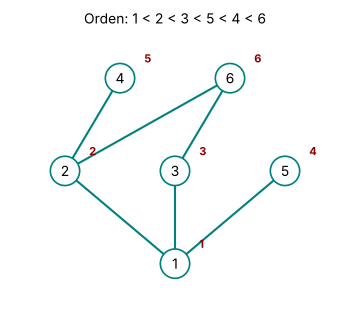

In [16]:
print(aristas_hasse(A, divide))
dibujar_hasse(A, divide, orden=[1, 2, 3, 5, 4, 6]);

### Todo junto

`mostrar_ordenes_topologicos` reúne lo anterior: aristas del diagrama, niveles, los dos algoritmos paso a paso y todas las clasificaciones (como mucho `maximo` de ellas).

In [17]:
def mostrar_ordenes_topologicos(elementos, menor, titulo=None,
                                pasos=True, maximo=50):
    """
    Muestra, para el orden parcial dado:
      1) las aristas del diagrama de Hasse,
      2) los niveles (anticadenas) por minimales y por maximales,
      3) el algoritmo paso a paso por minimales y por maximales (si pasos=True),
      4) TODOS los órdenes topológicos (como mucho `maximo` de ellos) y cuántos hay.
    Devuelve la lista de órdenes mostrados.
    """
    elementos = list(elementos)
    linea = "=" * 64
    print(linea)
    print(titulo or "Órdenes topológicos")
    print(linea)
    print("Elementos:", _fmt(elementos))

    aristas = aristas_hasse(elementos, menor)
    print("Aristas del diagrama de Hasse (a -- b con a < b):")
    print("  " + ", ".join(f"{a}--{b}" for a, b in aristas) if aristas else "  (ninguna)")

    print("Niveles por minimales (de abajo arriba):")
    for i, nivel in enumerate(niveles_minimales(elementos, menor), 1):
        print(f"  nivel {i}: {_fmt(nivel)}")
    print("Niveles por maximales (de abajo arriba):")
    for i, nivel in enumerate(niveles_maximales(elementos, menor), 1):
        print(f"  nivel {i}: {_fmt(nivel)}")

    if pasos:
        print()
        mostrar_pasos(elementos, menor, "minimales")
        print()
        mostrar_pasos(elementos, menor, "maximales")

    print()
    ordenes = list(islice(todos_los_ordenes_topologicos(elementos, menor), maximo))
    total = sum(1 for _ in todos_los_ordenes_topologicos(elementos, menor))
    print(f"Todos los órdenes topológicos: {total}")
    ancho = len(str(len(ordenes)))
    for i, orden in enumerate(ordenes, 1):
        print(f"  T{i:<{ancho}} : {_fmt_orden(orden)}")
    if total > len(ordenes):
        print(f"  ... (se muestran {len(ordenes)} de {total})")
    print()
    return ordenes

In [18]:
mostrar_ordenes_topologicos(A, divide, "Divisibilidad en {1, ..., 6}", maximo=10);

Divisibilidad en {1, ..., 6}
Elementos: {1, 2, 3, 4, 5, 6}
Aristas del diagrama de Hasse (a -- b con a < b):
  1--2, 1--3, 1--5, 2--4, 2--6, 3--6
Niveles por minimales (de abajo arriba):
  nivel 1: {1}
  nivel 2: {2, 3, 5}
  nivel 3: {4, 6}
Niveles por maximales (de abajo arriba):
  nivel 1: {1}
  nivel 2: {2, 3}
  nivel 3: {4, 5, 6}

Algoritmo por minimales:
  paso  restantes           minimales  elegido
     1  {1, 2, 3, 4, 5, 6}  {1}        1
     2  {2, 3, 4, 5, 6}     {2, 3, 5}  2
     3  {3, 4, 5, 6}        {3, 4, 5}  3
     4  {4, 5, 6}           {4, 5, 6}  4
     5  {5, 6}              {5, 6}     5
     6  {6}                 {6}        6
  Orden obtenido: 1 < 2 < 3 < 4 < 5 < 6

Algoritmo por maximales:
  paso  restantes           maximales  elegido
     1  {1, 2, 3, 4, 5, 6}  {4, 5, 6}  4
     2  {1, 2, 3, 5, 6}     {5, 6}     5
     3  {1, 2, 3, 6}        {6}        6
     4  {1, 2, 3}           {2, 3}     2
     5  {1, 3}              {3}        3
     6  {1}                

## 6. El algoritmo de Kahn

**Coste del algoritmo por minimales.** Con $k$ elementos restantes, ver si cada $x$ es minimal exige compararlo con los otros $k-1$: son $k(k-1)\approx k^2$ llamadas a `menor` por paso. Como $k$ va de $n$ a $1$, el total es

$$\sum_{k=1}^{n}k(k-1)=\frac{(n+1)n(n-1)}{3}\approx\frac{n^3}{3}.$$

**Kahn (1962)** propuso llevar la cuenta en lugar de recalcular:

1. **Grado de entrada** $g(x)$: número de flechas que llegan a $x$ (basta el diagrama de Hasse). Los $x$ con $g(x)=0$ son los minimales y se ponen en una **cola**.
2. Mientras haya elementos en la cola: sacar $x$ y añadirlo a la lista; a cada sucesor $y$ de $x$ se le resta $1$ a $g(y)$ y, si llega a $0$, $y$ entra en la cola.
3. Si la lista final no tiene todos los elementos, hay un ciclo.

Cada elemento entra una vez en la cola y cada par se mira una vez: unas $n+m$ operaciones, con $m$ el número de pares ($m\le n(n-1)/2$).

Ahora la relación se da como una lista de pares $(a,b)$ con $a<b$.

In [19]:
def pares_desde_menor(elementos, menor):
    """Lista de pares (a, b) con a < b a partir de la función `menor`."""
    elementos = list(elementos)
    return [(a, b) for a in elementos for b in elementos if a != b and menor(a, b)]

def orden_topologico_kahn(elementos, pares):
    """
    Algoritmo de Kahn. `pares` son los pares (a, b) con a < b; basta con
    las aristas del diagrama de Hasse. Coste O(n + m), con n elementos y
    m pares: cada elemento entra una vez en la cola y cada par se mira una vez.
    """
    elementos = list(elementos)
    sucesores = {x: [] for x in elementos}
    grado = {x: 0 for x in elementos}          # grado de entrada
    for a, b in pares:
        if a != b:
            sucesores[a].append(b)
            grado[b] += 1
    cola = deque(x for x in elementos if grado[x] == 0)   # los minimales
    resultado = []
    while cola:
        x = cola.popleft()
        resultado.append(x)
        for y in sucesores[x]:                  # quitar x: sus sucesores
            grado[y] -= 1                       # pierden una entrada
            if grado[y] == 0:
                cola.append(y)                  # y pasa a ser minimal
    if len(resultado) < len(elementos):
        _error_ciclo()
    return resultado

def mostrar_kahn(elementos, pares):
    """Muestra el algoritmo de Kahn paso a paso: cola, elemento que sale y grados."""
    elementos = list(elementos)
    sucesores = {x: [] for x in elementos}
    grado = {x: 0 for x in elementos}
    for a, b in pares:
        if a != b:
            sucesores[a].append(b)
            grado[b] += 1
    print("Grados de entrada:", ", ".join(f"{x}:{grado[x]}" for x in elementos))
    cola = deque(x for x in elementos if grado[x] == 0)
    resultado = []
    filas = []
    while cola:
        antes = _fmt(cola)
        x = cola.popleft()
        resultado.append(x)
        cambios = []
        for y in sucesores[x]:
            grado[y] -= 1
            cambios.append(f"{y}:{grado[y]}")
            if grado[y] == 0:
                cola.append(y)
        filas.append((antes, str(x), ", ".join(cambios) or "-"))
    a1 = max(len("cola"), *(len(f[0]) for f in filas))
    print(f"  {'paso':>4}  {'cola':<{a1}}  sale  nuevos grados")
    for paso, (c, x, g) in enumerate(filas, 1):
        print(f"  {paso:>4}  {c:<{a1}}  {x:<4}  {g}")
    if len(resultado) < len(elementos):
        _error_ciclo()
    print("  Orden obtenido:", _fmt_orden(resultado))
    return resultado

In [20]:
H = aristas_hasse(A, divide)
print(H)
print(orden_topologico_kahn(A, H))
print()
mostrar_kahn(A, H);

[(1, 2), (1, 3), (1, 5), (2, 4), (2, 6), (3, 6)]
[1, 2, 3, 5, 4, 6]

Grados de entrada: 1:0, 2:1, 3:1, 4:1, 5:1, 6:2
  paso  cola       sale  nuevos grados
     1  {1}        1     2:0, 3:0, 5:0
     2  {2, 3, 5}  2     4:0, 6:1
     3  {3, 5, 4}  3     6:0
     4  {5, 4, 6}  5     -
     5  {4, 6}     4     -
     6  {6}        6     -
  Orden obtenido: 1 < 2 < 3 < 5 < 4 < 6


El $6$ tiene grado de entrada $2$ (le llegan aristas desde $2$ y $3$): sólo entra en la cola cuando han salido los dos. Con todos los pares de la relación, y no sólo las aristas de Hasse, el resultado es el mismo:

In [21]:
P = pares_desde_menor(A, divide)
print(len(P), "pares:", P)
print(orden_topologico_kahn(A, P))

8 pares: [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (2, 4), (2, 6), (3, 6)]
[1, 2, 3, 5, 4, 6]


### Comparación de tiempos

Tomamos los divisores de un número con muchos divisores y medimos los dos algoritmos. Para Kahn usamos las aristas del diagrama de Hasse, que se calculan una sola vez y fuera de la medida.

In [22]:
def divisores(N):
    return [d for d in range(1, N + 1) if N % d == 0]

def cubre(a, b):
    # b cubre a a en la divisibilidad: b = a * p con p primo
    if b % a:
        return False
    q = b // a
    return q > 1 and all(q % p for p in range(2, int(q**0.5) + 1))

for N in (720, 5040, 55440, 720720):
    D = divisores(N)
    H = [(a, b) for a in D for b in D if cubre(a, b)]
    t0 = time.perf_counter(); o1 = orden_topologico_minimales(D, divide); t1 = time.perf_counter()
    o2 = orden_topologico_kahn(D, H); t2 = time.perf_counter()
    assert es_orden_topologico(o2, divide)
    print(f"N = {N:>6}: {len(D):>3} divisores, {len(H):>4} aristas | "
          f"minimales {t1 - t0:8.4f} s | Kahn {t2 - t1:8.6f} s")

N =    720:  30 divisores,   59 aristas | minimales   0.0004 s | Kahn 0.000032 s
N =   5040:  60 divisores,  148 aristas | minimales   0.0020 s | Kahn 0.000063 s
N =  55440: 120 divisores,  356 aristas | minimales   0.0140 s | Kahn 0.000280 s


N = 720720: 240 divisores,  832 aristas | minimales   0.0877 s | Kahn 0.000440 s


## 7. Más ejemplos

### Ejercicio 3.32

$A=\{1,2,3,4\}$ y $\mathcal R=\{(1,4),(3,1),(3,2),(3,4)\}\cup\Delta$.

In [23]:
R332 = {(1, 4), (3, 1), (3, 2), (3, 4)}
mostrar_ordenes_topologicos([1, 2, 3, 4], desde_pares(R332), "Ejercicio 3.32");

Ejercicio 3.32
Elementos: {1, 2, 3, 4}
Aristas del diagrama de Hasse (a -- b con a < b):
  1--4, 3--1, 3--2
Niveles por minimales (de abajo arriba):
  nivel 1: {3}
  nivel 2: {1, 2}
  nivel 3: {4}
Niveles por maximales (de abajo arriba):
  nivel 1: {3}
  nivel 2: {1}
  nivel 3: {2, 4}

Algoritmo por minimales:
  paso  restantes     minimales  elegido
     1  {1, 2, 3, 4}  {3}        3
     2  {1, 2, 4}     {1, 2}     1
     3  {2, 4}        {2, 4}     2
     4  {4}           {4}        4
  Orden obtenido: 3 < 1 < 2 < 4

Algoritmo por maximales:
  paso  restantes     maximales  elegido
     1  {1, 2, 3, 4}  {2, 4}     2
     2  {1, 3, 4}     {4}        4
     3  {1, 3}        {1}        1
     4  {3}           {3}        3
  Orden obtenido: 3 < 1 < 4 < 2

Todos los órdenes topológicos: 3
  T1 : 3 < 1 < 2 < 4
  T2 : 3 < 1 < 4 < 2
  T3 : 3 < 2 < 1 < 4



### Vestirse

Un par $(a,b)$ significa que la prenda $a$ debe ponerse antes que la $b$.

In [24]:
R = {("calcetines", "zapatos"), ("pantalón", "zapatos"),
     ("pantalón", "cinturón"), ("camisa", "cinturón"),
     ("camisa", "corbata"), ("corbata", "chaqueta"),
     ("cinturón", "chaqueta")}
E = ["chaqueta", "zapatos", "corbata", "cinturón",
     "camisa", "pantalón", "calcetines"]
menor = desde_pares(R)

mostrar_ordenes_topologicos(E, menor, "Vestirse", pasos=False, maximo=5)
print("Kahn:", _fmt_orden(orden_topologico_kahn(E, R)))

Vestirse
Elementos: {chaqueta, zapatos, corbata, cinturón, camisa, pantalón, calcetines}
Aristas del diagrama de Hasse (a -- b con a < b):
  calcetines--zapatos, camisa--cinturón, camisa--corbata, cinturón--chaqueta, corbata--chaqueta, pantalón--cinturón, pantalón--zapatos
Niveles por minimales (de abajo arriba):
  nivel 1: {camisa, pantalón, calcetines}
  nivel 2: {zapatos, corbata, cinturón}
  nivel 3: {chaqueta}
Niveles por maximales (de abajo arriba):
  nivel 1: {camisa, pantalón}
  nivel 2: {corbata, cinturón, calcetines}
  nivel 3: {chaqueta, zapatos}

Todos los órdenes topológicos: 91
  T1 : camisa < corbata < pantalón < cinturón < chaqueta < calcetines < zapatos
  T2 : camisa < corbata < pantalón < cinturón < calcetines < chaqueta < zapatos
  T3 : camisa < corbata < pantalón < cinturón < calcetines < zapatos < chaqueta
  T4 : camisa < corbata < pantalón < calcetines < zapatos < cinturón < chaqueta
  T5 : camisa < corbata < pantalón < calcetines < cinturón < chaqueta < zapatos
 

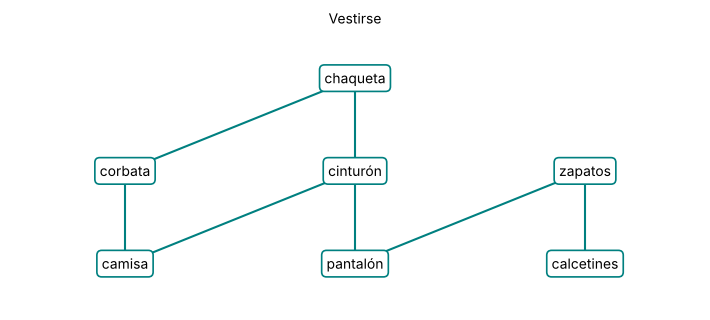

In [25]:
dibujar_hasse(E, menor, titulo="Vestirse");

### Detección de ciclos

Si la relación tiene un ciclo no es un orden parcial: llega un momento en que no queda ningún minimal (y, en Kahn, la cola se vacía antes de tiempo).

In [26]:
ciclo = {(1, 2), (2, 3), (3, 1)}
for f, args in ((orden_topologico_minimales, ([1, 2, 3], desde_pares(ciclo))),
                (orden_topologico_kahn, ([1, 2, 3], ciclo))):
    try:
        f(*args)
    except ValueError as e:
        print(f.__name__, "->", e)

orden_topologico_minimales -> Hay un ciclo: la relación no es un orden parcial
orden_topologico_kahn -> Hay un ciclo: la relación no es un orden parcial


## Referencias

- Kahn, A. B. (1962). Topological sorting of large networks. *Communications of the ACM*, 5(11), 558–562.
- Grimaldi, R. P. (1998). *Matemática discreta y combinatoria* (3ª ed.). Addison Wesley Longman.
- Rosen, K. H. (2004). *Matemática discreta y sus aplicaciones* (5ª ed.). McGraw-Hill.